In [47]:
import math

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans


import warnings
warnings.filterwarnings('ignore')

### <font color = lightblue> Projeto de Segmentação de Clientes

In [48]:
# Banco de dados - LIT - SAINT PAUL
fonte = 'https://raw.githubusercontent.com/Diego-Sarti-19/02-customer-segmentation-RFM-model/refs/heads/main/Dados/OlistEcommerce.csv'
df=pd.read_csv(fonte)
df.head(5)

,amostra,id_cliente,id_unico_cliente,item_id,cep_cliente,cidade_cliente,estado_cliente,id_pedido,status_pedido,horario_pedido,...,pagamento_sequencial,pagamento_tipo,pagamento_prestacoes,pagamento_valor,review,categoria,categoria_ingles,cep_vendedor,cidade_vendedor,estado_vendedor
0,0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,1,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,...,1,credit_card,2,146.87,4,moveis_escritorio,office_furniture,8577,itaquaquecetuba,SP
1,1,8912fc0c3bbf1e2fbf35819e21706718,9eae34bbd3a474ec5d07949ca7de67c0,1,68030,santarem,PA,c1d2b34febe9cd269e378117d6681172,delivered,2017-11-09 00:50:13,...,1,credit_card,1,275.79,1,moveis_escritorio,office_furniture,8577,itaquaquecetuba,SP
2,2,8912fc0c3bbf1e2fbf35819e21706718,9eae34bbd3a474ec5d07949ca7de67c0,2,68030,santarem,PA,c1d2b34febe9cd269e378117d6681172,delivered,2017-11-09 00:50:13,...,1,credit_card,1,275.79,1,moveis_escritorio,office_furniture,8577,itaquaquecetuba,SP
3,3,f0ac8e5a239118859b1734e1087cbb1f,3c799d181c34d51f6d44bbbc563024db,1,92480,nova santa rita,RS,b1a5d5365d330d10485e0203d54ab9e8,delivered,2017-05-07 20:11:26,...,1,credit_card,7,140.61,3,moveis_escritorio,office_furniture,8577,itaquaquecetuba,SP
4,4,6bc8d08963a135220ed6c6d098831f84,23397e992b09769faf5e66f9e171a241,1,25931,mage,RJ,2e604b3614664aa66867856dba7e61b7,delivered,2018-02-03 19:45:40,...,1,credit_card,10,137.58,4,moveis_escritorio,office_furniture,8577,itaquaquecetuba,SP


In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 116581 entries, 0 to 116580
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   amostra               116581 non-null  int64  
 1   id_cliente            116581 non-null  str    
 2   id_unico_cliente      116581 non-null  str    
 3   item_id               116581 non-null  int64  
 4   cep_cliente           116581 non-null  int64  
 5   cidade_cliente        116581 non-null  str    
 6   estado_cliente        116581 non-null  str    
 7   id_pedido             116581 non-null  str    
 8   status_pedido         116581 non-null  str    
 9   horario_pedido        116581 non-null  str    
 10  pedido_aprovado       116567 non-null  str    
 11  pedido_entregador     115368 non-null  str    
 12  pedido_entregue       114066 non-null  str    
 13  data_estimada         116581 non-null  str    
 14  id_vendedor           116581 non-null  str    
 15  preco      

In [4]:
df.head(1)

,amostra,id_cliente,id_unico_cliente,item_id,cep_cliente,cidade_cliente,estado_cliente,id_pedido,status_pedido,horario_pedido,...,pagamento_sequencial,pagamento_tipo,pagamento_prestacoes,pagamento_valor,review,categoria,categoria_ingles,cep_vendedor,cidade_vendedor,estado_vendedor
0,0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,1,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,...,1,credit_card,2,146.87,4,moveis_escritorio,office_furniture,8577,itaquaquecetuba,SP


In [5]:
df.columns

Index(['amostra', 'id_cliente', 'id_unico_cliente', 'item_id', 'cep_cliente',
       'cidade_cliente', 'estado_cliente', 'id_pedido', 'status_pedido',
       'horario_pedido', 'pedido_aprovado', 'pedido_entregador',
       'pedido_entregue', 'data_estimada', 'id_vendedor', 'preco', 'frete',
       'pagamento_sequencial', 'pagamento_tipo', 'pagamento_prestacoes',
       'pagamento_valor', 'review', 'categoria', 'categoria_ingles',
       'cep_vendedor', 'cidade_vendedor', 'estado_vendedor'],
      dtype='str')

### Análise Exploratória

In [6]:
# st - segmento de dados, por estado.
def plot_perc(st,dados):
    plt.figure(figsize=(20,8))

    g = sns.countplot(
        x=st, data=dados, 
        orient='h', 
        palette='muted', 
        order=dados[st].value_counts().index)
    g.set_title("Distribuição do estado dos clientes", fontsize=20)
    g.set_xlabel("Estado", fontsize=17)
    g.set_ylabel("Contagem", fontsize=17)
    g.set_xticklabels(g.get_xticklabels(),rotation=45)
    sizes = []
    for p in g.patches:
        height = p.get_height()
        sizes.append(height)
        g.text(p.get_x()+p.get_width()/1.6,
            height + 200,
            '{:1.2f}%'.format(height/116581*100),
            ha="center", va='bottom',fontsize=12) 
    g.set_ylim(0, max(sizes) * 1.1)

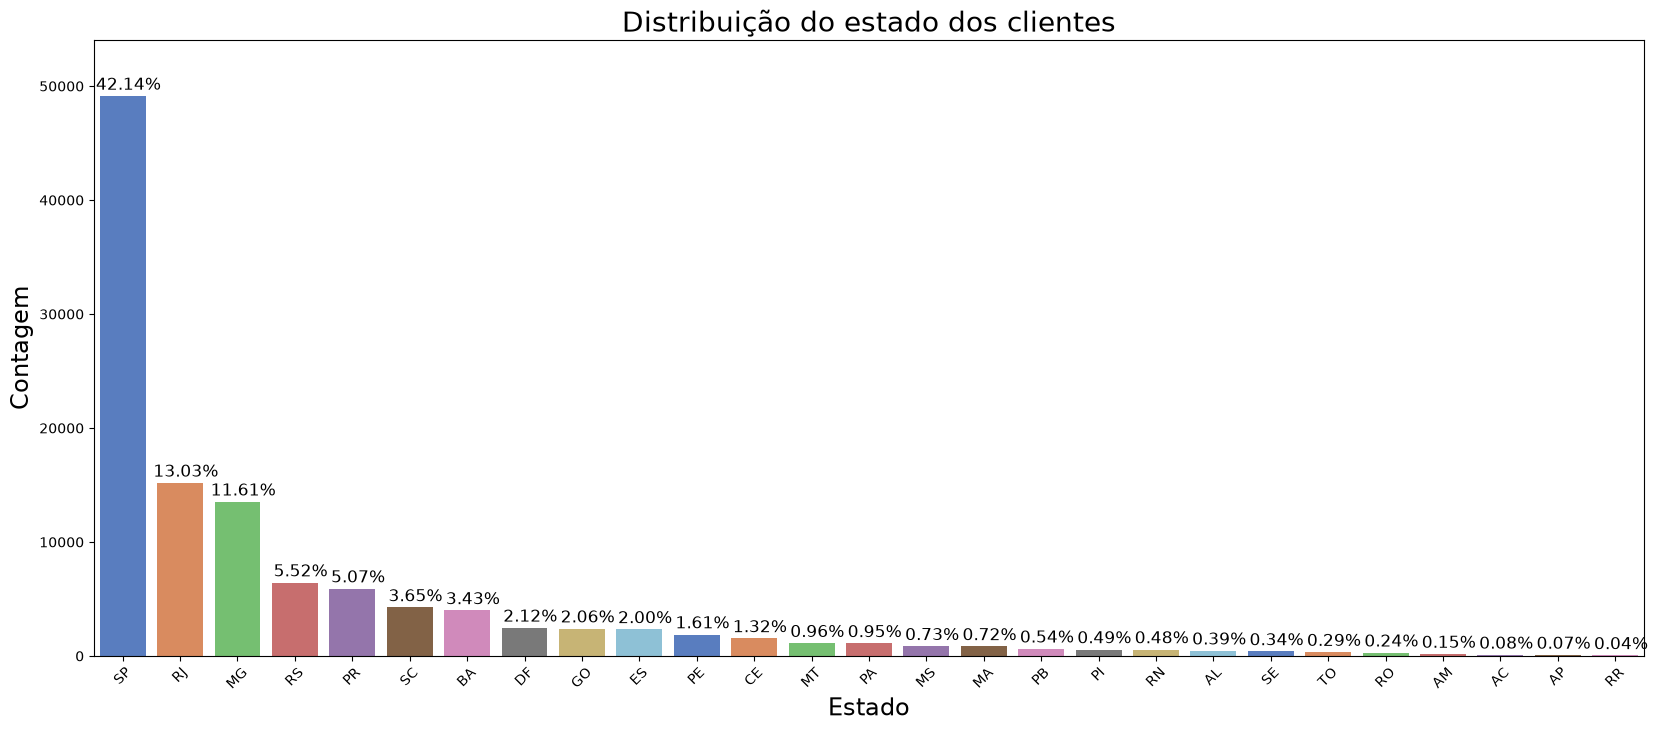

In [7]:
# Gráfico de distribuição de clientes por estado
plot_perc('estado_cliente',df)

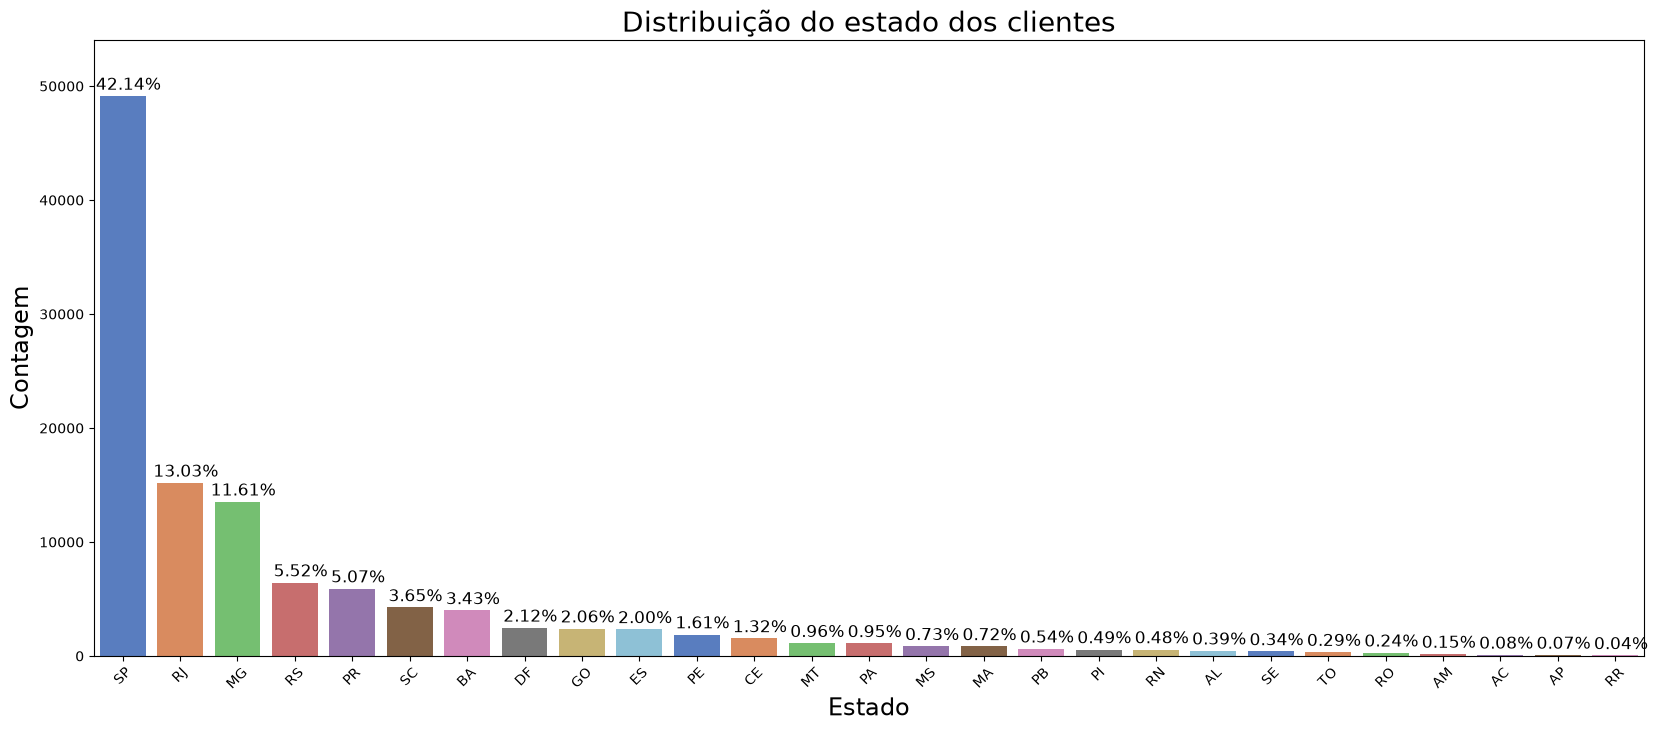

In [8]:
# Gráfico de distribuição de vendendores por estado
plot_perc('estado_cliente',df)

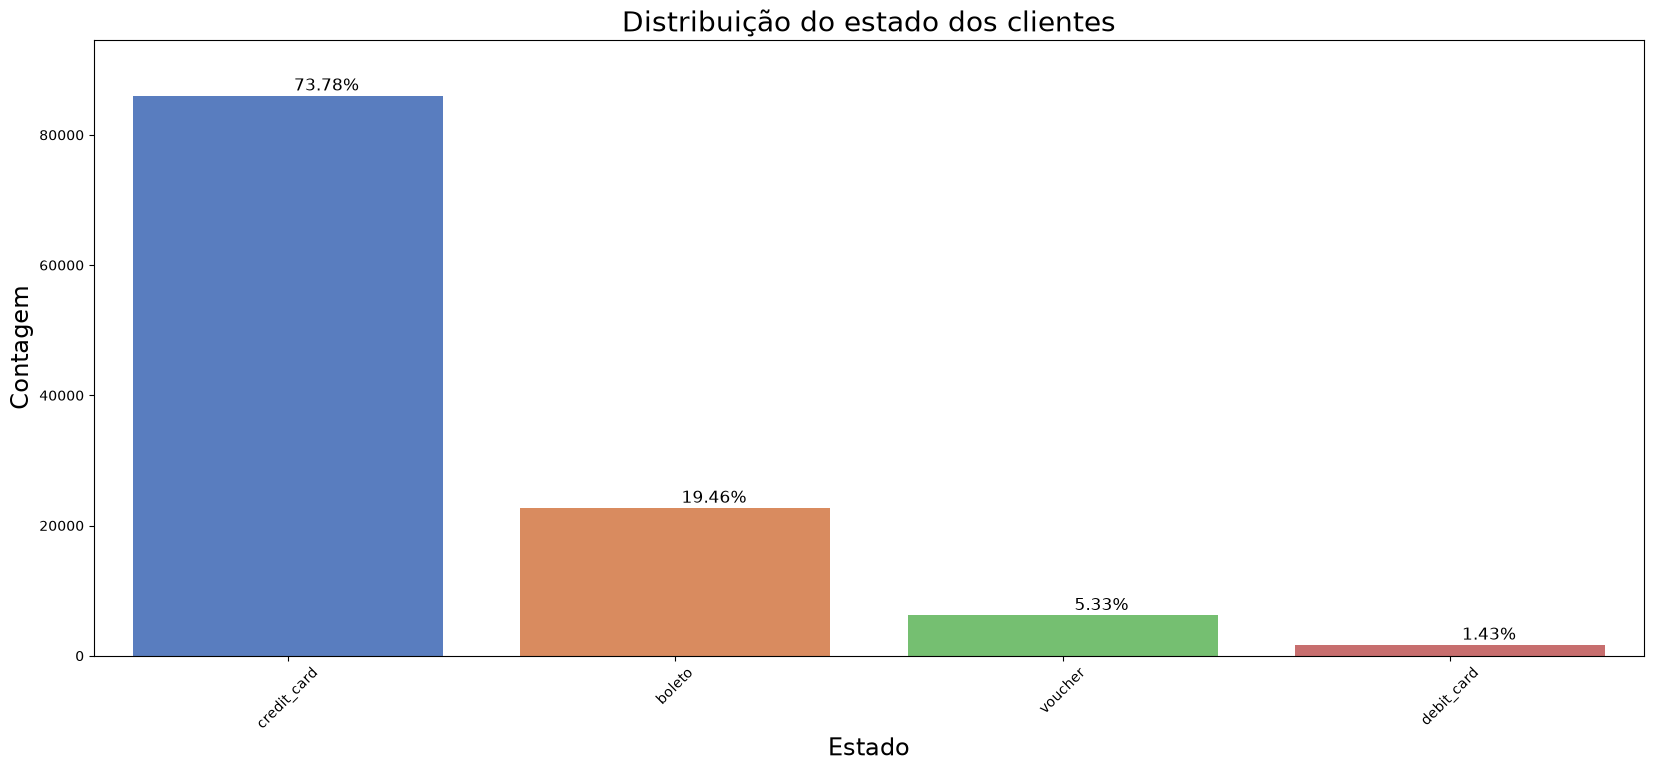

In [9]:
# Análise quanto a forma de pagamento utilizada pelos clientes
plot_perc('pagamento_tipo',df)

- Meios de pagamento: Observa-se a predominância de compras realizadas com cartão de crédito, seguido por boleto bancário, voucher e cartão de débito. Uma oportunidade a ser avaliada é a ampliação de campanhas promocionais que incentivem pagamentos à vista, especialmente via boleto bancário e cartão de débito, visando diversificar os meios de pagamento utilizados pelos clientes.

- Distribuição geográfica: Observa-se uma concentração de vendedores e compradores no estado de São Paulo (SP), indicando uma maior representatividade desse mercado na base analisada.

Separação das variáveis de interesse

In [10]:
df_olist = df[['id_unico_cliente', 'id_cliente', 'horario_pedido', 'item_id', 'preco']]

In [11]:

# Dataframe com a data da última compra de cada cliente - Data de Compra
df_compra = df.groupby('id_unico_cliente').horario_pedido.max().reset_index()
df_compra.columns = ['id_unico_cliente', 'DataMaxCompra']

In [12]:
# seleciona o ponto de observação como a data máxima de compra em nosso df 
# (CONSIDERANDO QUE O DATASET É DE 2018, A DATA MÁXIMA DE COMPRA É 2018-09-03)
# Conversão em dataframe para o cálculo da recência
df_compra['DataMaxCompra']= pd.to_datetime(df_compra['DataMaxCompra'])

> Precisamos definir agora as três variáveis que utilizaremos para segmentação: 
**recência**, 
**frequência**,  
**receita**. 

> - Recência: quão recentemente um cliente fez uma compra. É um importante preditor, pois um cliente que comprou há pouco tempo tem mais chance de voltar a comprar do que aquele que comprou há muito tempo, além de apresentar uma probabilidade maior de responder a promoções.
> - Frequência: com que frequência um cliente faz uma compra.  Se um cliente compra frequentemente, espera-se que ele volte a comprar.
> - Receita: quanto dinheiro um cliente gasta em compras. Aqueles clientes que gastaram muito têm mais valor para a organização em comparação com aqueles que gastaram menos

In [13]:
# Recência: número de dias desde a última compra do cliente até a data máxima de compra do dataset.
df_compra['Recencia'] = (
    df_compra['DataMaxCompra'].max() - df_compra['DataMaxCompra']
    ).dt.days

#junta esse df com o nosso novo chamado df_user
df_usuario = pd.merge(df_olist, df_compra[['id_unico_cliente','Recencia']], on='id_unico_cliente')

df_usuario.head()

,id_unico_cliente,id_cliente,horario_pedido,item_id,preco,Recencia
0,861eff4711a542e4b93843c6dd7febb0,06b8999e2fba1a1fbc88172c00ba8bc7,2017-05-16 15:05:35,1,124.99,474
1,9eae34bbd3a474ec5d07949ca7de67c0,8912fc0c3bbf1e2fbf35819e21706718,2017-11-09 00:50:13,1,112.99,298
2,9eae34bbd3a474ec5d07949ca7de67c0,8912fc0c3bbf1e2fbf35819e21706718,2017-11-09 00:50:13,2,112.99,298
3,3c799d181c34d51f6d44bbbc563024db,f0ac8e5a239118859b1734e1087cbb1f,2017-05-07 20:11:26,1,124.99,483
4,23397e992b09769faf5e66f9e171a241,6bc8d08963a135220ed6c6d098831f84,2018-02-03 19:45:40,1,106.99,211


In [14]:
# plotando a distribuição da feature continua que acabamos de identificar
def dist(dados):
   sns.set(palette='muted', color_codes=True, style='white')
   fig, ax = plt.subplots(figsize=(12, 6))
   sns.despine(left=True)
   sns.distplot(dados, bins=30)
   plt.show()

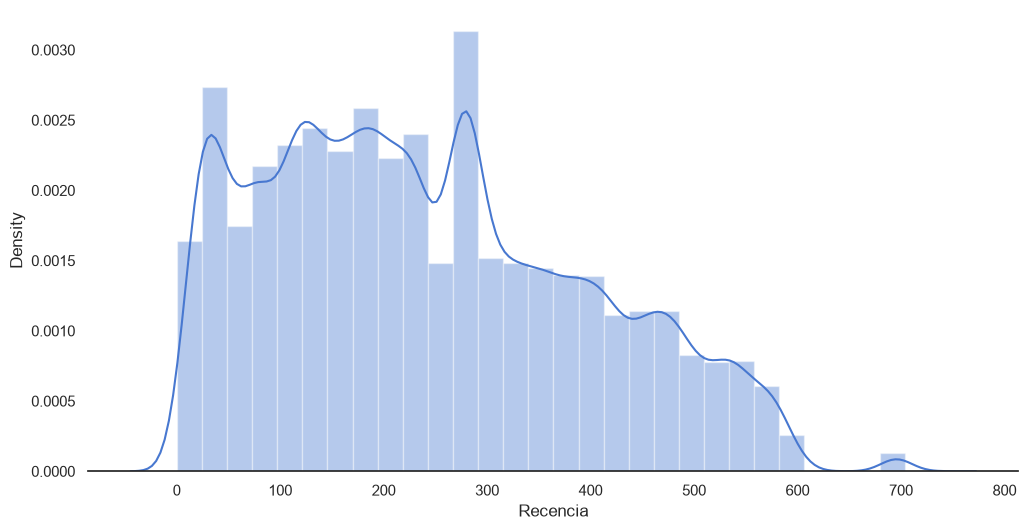

In [15]:
# Distribuição da feature recência.
dist(df_usuario['Recencia'])

> - Recência: quão recentemente um cliente fez uma compra.
 - cerca de 0.03% dos clientes fizeram uma compra ao redor 300 dias.
- Há poucos registros de clientes que fizeram compras há mais de 700 dias.
- A distribuição da recência é assimétrica à direita, com uma cauda longa à direita. I
- Isso indica que a maioria dos clientes fez compras recentemente.

In [16]:
# Método do cotovelo para determinar o número ideal de clusters 
# Utilizar dados naturales, sem padronização, para o cálculo do WCSS (Within-Cluster Sum of Squares)
def calcular_wcss(data):
    wcss = []
    for k in range(1, 10):
        kmeans = KMeans(n_clusters=k,
                init='k-means++',
                random_state=42,
                max_iter=300, 
                n_init=10, 
                algorithm='lloyd')
        kmeans.fit(X=data)
        data["clusters"] = kmeans.labels_
        wcss.append(kmeans.inertia_)
    return wcss

> Agora precisamos usar o Método Cotovelo, a ideia é rodar o KMeans para várias quantidades diferentes de clusters e dizer qual dessas quantidades é o número ótimo de clusters. Usando a "regra do cotovelo", identificamos que a partir de 4 clusters teremos bons resultados. Vou usar 5 apenas para garantir.

> O que geralmente acontece ao aumentar a quantidade de clusters no KMeans é que as diferenças entre clusters se tornam muito pequenas, e as diferenças das observações intra-clusters vão aumentando. Então é preciso achar um equilíbrio em que as observações que formam cada agrupamento sejam o mais homogêneas possível e que os agrupamentos formados sejam o mais diferentes um dos outros.

In [ ]:
# df_recencia = df_usuario[['Recencia_Padronizada']]
df_recencia = df_usuario[['Recencia']]
    
soma_quadrados = calcular_wcss(df_recencia)

> Mas como podemos identificar se o melhor número de clusters é 3, 4 ou 5? Existe uma solução matemática! Primeiramente, definimos uma reta ligando o primeiro ponto (cluster 1) ao último ponto (cluster 9). Então, calculamos a distância de cada ponto até a reta usando a equação da distência euclidiana.

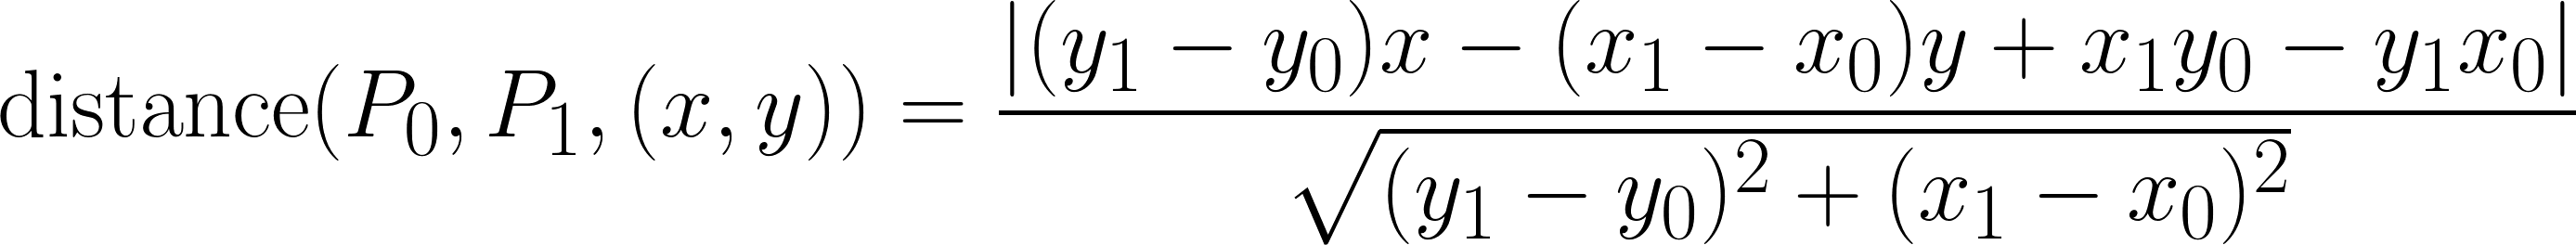

In [18]:
# Within-Cluster Sum of Squares
# A ideia é encontrar o ponto em que aumentar o número de clusters deixa de trazer uma redução tão expressiva na variabilidade interna dos grupos.

def numero_otimo_clusters(wcss):
    x1, y1 = 2, wcss[0]
    x2, y2 = 20, wcss[len(wcss)-1]

    distancias = []
    for i in range(len(wcss)):
        x0 = i+2
        y0 = wcss[i]
        numerador = abs((y2-y1)*x0 - (x2-x1)*y0 + x2*y1 - y2*x1)
        denominador = math.sqrt((y2 - y1)**2 + (x2 - x1)**2)
        distancias.append(numerador/denominador)
    
    return distancias.index(max(distancias)) + 2


In [19]:
print("Número ótimo de clusters: ", numero_otimo_clusters(soma_quadrados))

Número ótimo de clusters:  4


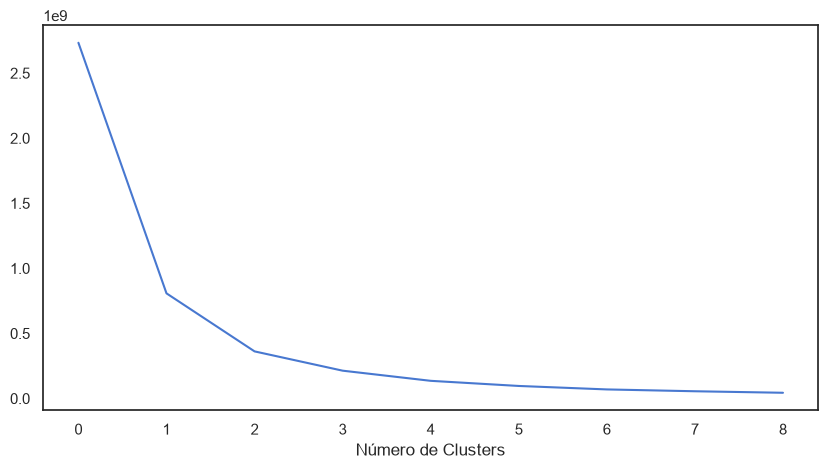

In [20]:
plt.figure(figsize=(10, 5))
plt.plot(soma_quadrados)
plt.xlabel("Número de Clusters")
plt.show()

In [21]:
# rodando o kmeans para nossa quantidade ótima de clusters
# parametros do KMeans ajustados para replicabilidade e performance
kmeans = KMeans(n_clusters=4,
                init='k-means++',
                random_state=42,
                max_iter=300, 
                n_init=10, 
                algorithm='lloyd')

df_usuario['RecenciaCluster'] = kmeans.fit_predict(df_recencia)

In [22]:
df_usuario.groupby('RecenciaCluster')['Recencia'].describe()

,count,mean,std,min,25%,50%,75%,max
RecenciaCluster,,,,,,,,
0,33639.0,187.911204,35.134736,128.0,158.0,187.0,218.0,254.0
1,20324.0,490.622269,59.293154,406.0,444.0,481.0,533.0,728.0
2,31790.0,66.790878,36.009443,0.0,33.0,67.0,100.0,127.0
3,30828.0,320.233294,43.971639,255.0,281.0,314.0,357.0,405.0


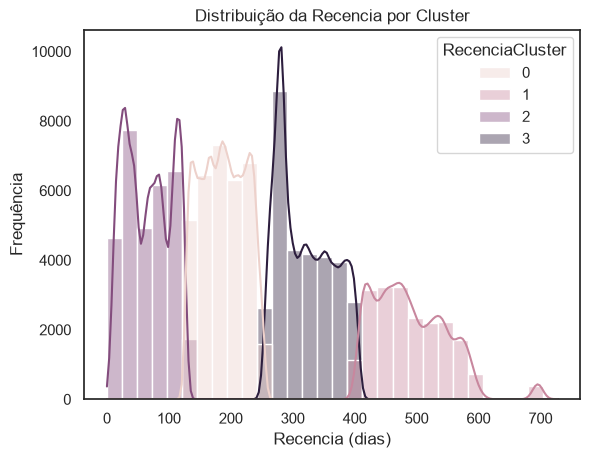

In [23]:
def dist_cluster(dados, variavel, cluster):
    sns.histplot(
        data=dados,
        x=variavel,
        hue=cluster,
        bins=30,
        kde=True,
        alpha=0.4
    )

    plt.title('Distribuição da ' + variavel + ' por Cluster')
    plt.xlabel(variavel + ' (dias)')
    plt.ylabel('Frequência')
    plt.show()

dist_cluster(df_usuario, 'Recencia', 'RecenciaCluster')


In [24]:
#função para ordenar o número de clusters 
def ordenar_cluster(cluster_nome, target_nome,df,ascending):
    novo_nome = 'novo' + cluster_nome
    agrupado_por_cluster = df.groupby(cluster_nome)[target_nome].mean().reset_index()
    agrupado_por_cluster_ordenado = agrupado_por_cluster.sort_values(by=target_nome,
                                                                     ascending=ascending).reset_index(drop=True)
    agrupado_por_cluster_ordenado['index'] = agrupado_por_cluster_ordenado.index
    juntando_cluster = pd.merge(df,agrupado_por_cluster_ordenado[[cluster_nome,'index']], on=cluster_nome)
    removendo_dados = juntando_cluster.drop([cluster_nome],axis=1)
    df_final = removendo_dados.rename(columns={"index":cluster_nome})
    return df_final

df_usuario = ordenar_cluster('RecenciaCluster', 'Recencia',df_usuario,False)

In [25]:
df_usuario.groupby('RecenciaCluster')['Recencia'].describe()

,count,mean,std,min,25%,50%,75%,max
RecenciaCluster,,,,,,,,
0,20324.0,490.622269,59.293154,406.0,444.0,481.0,533.0,728.0
1,30828.0,320.233294,43.971639,255.0,281.0,314.0,357.0,405.0
2,33639.0,187.911204,35.134736,128.0,158.0,187.0,218.0,254.0
3,31790.0,66.790878,36.009443,0.0,33.0,67.0,100.0,127.0


In [26]:
# cria um df com a quantidade de ordens para cada cliente
df_frequencia = df.groupby('id_unico_cliente').pedido_aprovado.count().reset_index()
df_frequencia.columns = ['id_unico_cliente','Frequencia']

# adiciona esses dados em nosso df principal
df_usuario = pd.merge(df_usuario, df_frequencia, on='id_unico_cliente')

In [27]:
df_usuario.head(1)

,id_unico_cliente,id_cliente,horario_pedido,item_id,preco,Recencia,RecenciaCluster,Frequencia
0,861eff4711a542e4b93843c6dd7febb0,06b8999e2fba1a1fbc88172c00ba8bc7,2017-05-16 15:05:35,1,124.99,474,0,1


In [28]:
# rodando a mesma quantidade ótima de clusters para a feature Frequência
df_frequencia = df_usuario[['Frequencia']]
kmeans = KMeans(n_clusters=4,
                init='k-means++',
                random_state=42,
                max_iter=300, 
                n_init=10, 
                algorithm='lloyd')


df_usuario['FrequenciaCluster'] = kmeans.fit_predict(df_frequencia)
# Trazer clusters ordenados para a feature Frequência, 
# onde o cluster 0 representa os clientes com maior frequência de compras.
df_usuario = ordenar_cluster('FrequenciaCluster', 'Frequencia',df_usuario,False)

In [29]:
df_usuario.groupby('FrequenciaCluster')['Frequencia'].describe()

,count,mean,std,min,25%,50%,75%,max
FrequenciaCluster,,,,,,,,
0,75.0,75.000000,0.000000,75.0,75.0,75.0,75.0,75.0
1,731.0,21.489740,6.588977,14.0,15.0,21.0,24.0,38.0
2,9205.0,5.644432,2.138491,4.0,4.0,5.0,6.0,13.0
3,106570.0,1.306343,0.570539,0.0,1.0,1.0,2.0,3.0


In [30]:
#calcula a receita para cada cliente
df_receita = df.groupby('id_unico_cliente').pagamento_valor.sum().reset_index()

#junta com o df principal
df_usuario = pd.merge(df_usuario, df_receita, on='id_unico_cliente')

In [31]:
# rodando o kmeans para nossa quantidade ótima de clusters
df_pagamento = df_usuario[['pagamento_valor']]
kmeans = KMeans(n_clusters=4,
                init='k-means++',
                random_state=42,
                max_iter=300, 
                n_init=10, 
                algorithm='lloyd')
df_usuario['ReceitaCluster'] = kmeans.fit_predict(df_pagamento)
# Trazer clusters ordenados para a feature Receita, 
# onde o cluster 0 representa os clientes com maior receita.
df_usuario = ordenar_cluster('ReceitaCluster', 'pagamento_valor',df_usuario,False)

In [32]:
df_usuario.groupby('ReceitaCluster')['pagamento_valor'].describe()

,count,mean,std,min,25%,50%,75%,max
ReceitaCluster,,,,,,,,
0,8.0,109312.640000,0.000000,109312.64,109312.64,109312.64,109312.64,109312.64
1,191.0,27358.656911,10032.832924,17069.76,19167.26,25051.89,30186.00,45256.00
2,1478.0,5900.843911,2894.129234,3083.40,3798.75,4875.25,7315.92,16313.60
3,114904.0,261.485763,377.283592,9.59,69.90,132.82,270.00,3080.96


> Calcularemos a pontuação geral do cliente baseado nesses clusters e também definimos 4 opções: inativo, business, master e premium. 

In [33]:
df_final = df_usuario.drop(['id_cliente','horario_pedido','item_id','preco'],axis=1)
df_final.head()

,id_unico_cliente,Recencia,RecenciaCluster,Frequencia,FrequenciaCluster,pagamento_valor,ReceitaCluster
0,861eff4711a542e4b93843c6dd7febb0,474,0,1,3,146.87,3
1,9eae34bbd3a474ec5d07949ca7de67c0,298,1,2,3,551.58,3
2,9eae34bbd3a474ec5d07949ca7de67c0,298,1,2,3,551.58,3
3,3c799d181c34d51f6d44bbbc563024db,483,0,1,3,140.61,3
4,23397e992b09769faf5e66f9e171a241,211,2,1,3,137.58,3


In [34]:
df_final.columns = ['Id_unico_cliente', 'Recencia', 'RecenciaCluster', 'Frequencia', 'FrequenciaCluster', 'Receita', 'ReceitaCluster']

In [35]:
# Pontuação baseada em clusters de Recência, Frequência e Receita
df_final['Pontuacao'] = df_usuario['RecenciaCluster'] + df_usuario['FrequenciaCluster'] + df_usuario['ReceitaCluster']
df_final.groupby('Pontuacao')[['Recencia','Frequencia','Receita']].mean()
df_final.head()

,Id_unico_cliente,Recencia,RecenciaCluster,Frequencia,FrequenciaCluster,Receita,ReceitaCluster,Pontuacao
0,861eff4711a542e4b93843c6dd7febb0,474,0,1,3,146.87,3,6
1,9eae34bbd3a474ec5d07949ca7de67c0,298,1,2,3,551.58,3,7
2,9eae34bbd3a474ec5d07949ca7de67c0,298,1,2,3,551.58,3,7
3,3c799d181c34d51f6d44bbbc563024db,483,0,1,3,140.61,3,6
4,23397e992b09769faf5e66f9e171a241,211,2,1,3,137.58,3,8


In [36]:
# Pontuação por cluster
resultado = (
    df_final
    .groupby('Pontuacao')[['Recencia', 'Frequencia', 'Receita']]
    .mean()
)
display(resultado)

,Recencia,Frequencia,Receita
Pontuacao,,,
3,379.990566,19.150943,26891.090094
4,433.742358,26.008734,6516.477074
5,445.072256,7.357573,2257.375692
6,465.133295,1.885007,423.482680
7,306.677601,1.740309,330.775927
8,180.365315,1.567304,268.862510
9,66.603836,1.300957,213.734372


In [37]:
df_final.head()

,Id_unico_cliente,Recencia,RecenciaCluster,Frequencia,FrequenciaCluster,Receita,ReceitaCluster,Pontuacao
0,861eff4711a542e4b93843c6dd7febb0,474,0,1,3,146.87,3,6
1,9eae34bbd3a474ec5d07949ca7de67c0,298,1,2,3,551.58,3,7
2,9eae34bbd3a474ec5d07949ca7de67c0,298,1,2,3,551.58,3,7
3,3c799d181c34d51f6d44bbbc563024db,483,0,1,3,140.61,3,6
4,23397e992b09769faf5e66f9e171a241,211,2,1,3,137.58,3,8


In [38]:
df_final.loc[df_final['Pontuacao']>=3,'Segmento'] = 'Business' 
df_final.loc[df_final['Pontuacao']>=6,'Segmento'] = 'Master' 
df_final.loc[df_final['Pontuacao']>=8,'Segmento'] = 'Premium' 

In [39]:
#
df_final.to_csv('RFM.csv', index=False)

In [40]:
# Análise das segmentações criadas
def plot_segmento(x,y,data):
    sns.set(palette='muted', color_codes=True, style='whitegrid')
    fig, axs = plt.subplots(1, 1, figsize=(7, 5))
    sns.despine(left=True)
    sns.scatterplot(x=x, y=y, hue='Segmento', data=data, size='Segmento', sizes=(50,150), size_order=['Premium','Master','Business','Inativo'])
    axs.set_title('Segmento de Cliente')
    plt.show()

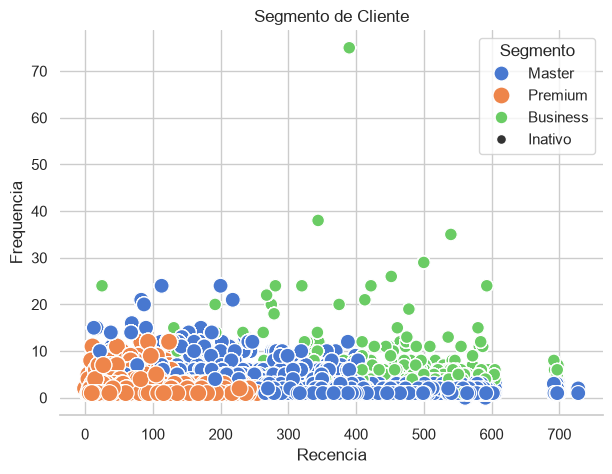

In [41]:
plot_segmento('Recencia','Frequencia',df_final)

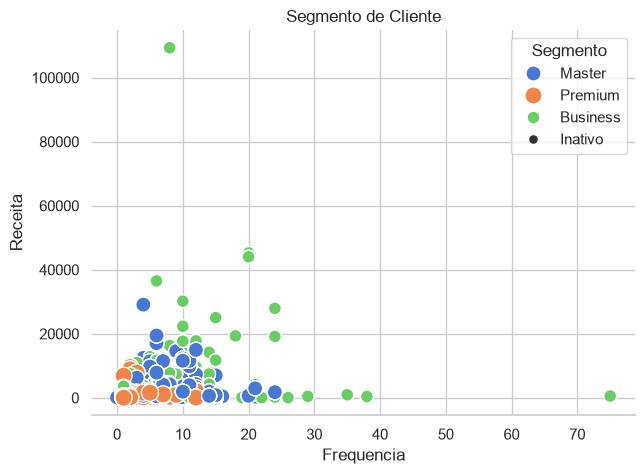

In [42]:
plot_segmento('Frequencia','Receita',df_final)

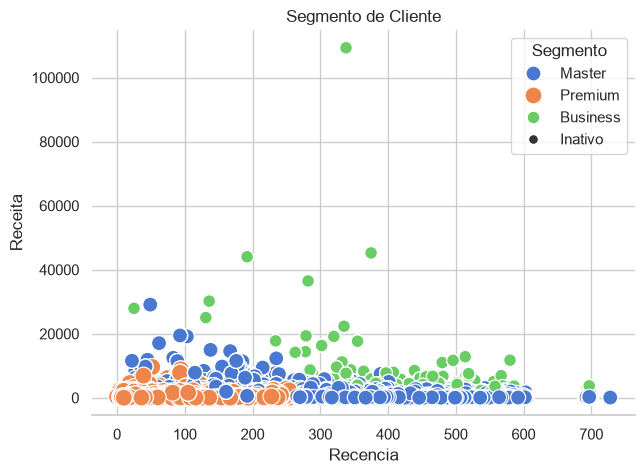

In [43]:
plot_segmento('Recencia','Receita',df_final)

In [44]:
df_final.columns

Index(['Id_unico_cliente', 'Recencia', 'RecenciaCluster', 'Frequencia',
       'FrequenciaCluster', 'Receita', 'ReceitaCluster', 'Pontuacao',
       'Segmento'],
      dtype='str')

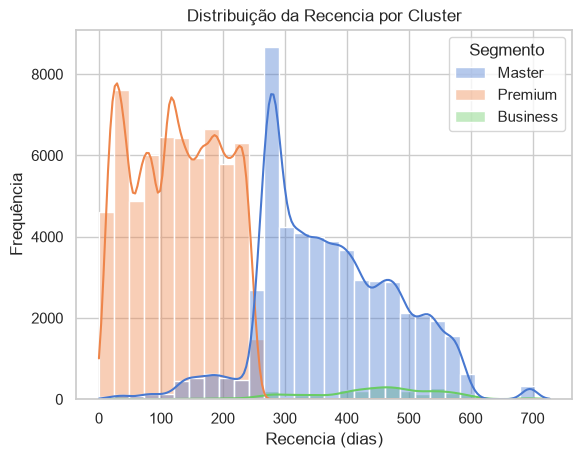

In [45]:
dist_cluster(df_final, 'Recencia', 'Segmento')


<Axes: xlabel='count', ylabel='Segmento'>

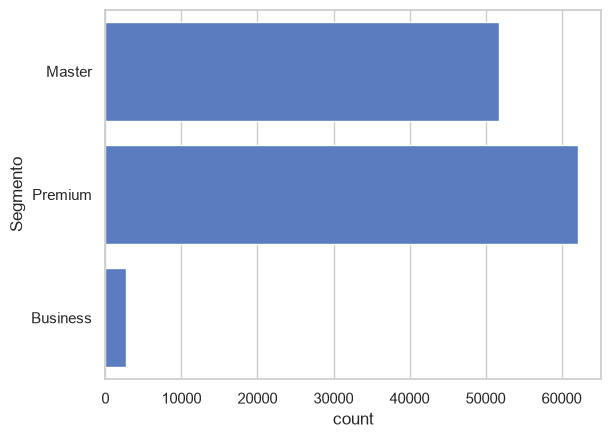

In [46]:
sns.countplot(df_final['Segmento'])